# PathSnap: show the actual outputs
**Open this notebook and scroll through its saved outputs, or use Run All.**
It loads the completed five-model experiment, displays the data and graphs,
and runs the trained classifiers again on one student-test trip.
It does not retrain, tune or run HMM decoding.

## Goal
Show: dataset → raw rows → candidates/features → five-model comparison → actual predictions.
Pointwise labels are estimated from reference routes, so Top-1 values are **proxies**.

## Setup
Use the project `.venv` Python kernel. In VS Code, open this notebook, choose
**Select Kernel → Python Environments → .venv**, then **Run All**.
The saved figures and tables are already visible without running cells.

In [1]:
from pathlib import Path
import sys, os, json
root_candidates = [Path.cwd(), Path.cwd().parent]
ROOT = next(p for p in root_candidates if (p / 'artifacts/model_comparison.csv').exists())
os.environ['MPLCONFIGDIR'] = str(ROOT / '.cache/matplotlib')
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'tools'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from show_outputs import fresh_predictions, comparison_figures, confusion_figure, NAMES
pd.set_option('display.max_columns', 14)
pd.set_option('display.width', 150)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
TRIP_ID = '00000000'  # Change to any supplied student-test trip.
print('Ready. Selected student-test trip:', TRIP_ID)

Ready. Selected student-test trip: 00000000


## Steps
### 1. Dataset counts and sampling
Source: the actual audit in `artifacts/eda/summary.json`.

In [2]:
summary = json.loads((ROOT / 'artifacts/eda/summary.json').read_text())
dataset_output = pd.DataFrame([
    {'Partition': name, 'Trips': s['trips'], 'GPS observations': s['gps_observations'],
     'Gaps >30 seconds': s['gaps_gt_30s'], 'Maximum gap (seconds)': s['sampling_quantiles_s']['max'],
     'Reference route breaks': s['reference_breaks']}
    for name, s in summary.items()
])
display(dataset_output)

,Partition,Trips,GPS observations,Gaps >30 seconds,Maximum gap (seconds),Reference route breaks
0,train,80,208417,133,153064.0,13
1,student_test,10,19160,2,210.0,1


### 2. Show real GPS rows and road arc rows

In [3]:
from pathsnap.io import DEFAULT_DATA
trip_path = ROOT / DEFAULT_DATA / 'student_test' / TRIP_ID / (TRIP_ID + '.track')
gps = pd.read_csv(trip_path, sep=r'\s+', header=None, names=['longitude', 'latitude', 'seconds'])
arcs = pd.read_csv(trip_path.with_suffix('.arcs'), sep=r'\s+', header=None, names=['from_node_id', 'to_node_id'])
reference = np.loadtxt(trip_path.with_suffix('.route'), dtype=int, ndmin=1)
print('GPS observations:', len(gps), '| Directed road arcs:', len(arcs), '| Reference route entries:', len(reference))
display(gps.head(8))
display(arcs.head(8).rename_axis('arc_id (zero-based row)'))
print('First 12 reference route arc IDs:', reference[:12].tolist())
print('A reference route entry is not a label for the corresponding GPS row.')

GPS observations: 2503 | Directed road arcs: 18196 | Reference route entries: 179


,longitude,latitude,seconds
0,54.963519,56.251559,1.0
1,54.963143,56.251523,2.0
2,54.962942,56.251470,3.0
3,54.962730,56.251532,4.0
4,54.962397,56.251549,5.0
5,54.962029,56.251666,6.0
6,54.961728,56.251676,7.0
7,54.961555,56.251657,8.0


,from_node_id,to_node_id
arc_id (zero-based row),,
0,0,2433
1,0,2475
2,0,2480
3,1,2
4,1,8408
5,2,2791
6,2,8394
7,3,8


First 12 reference route arc IDs: [17630, 17633, 211, 17638, 17645, 17659, 17674, 208, 10764, 501, 497, 10753]
A reference route entry is not a label for the corresponding GPS row.


### 3. Actual candidate features
Candidates were generated within 60 metres, capped at eight per GPS row.
Features contain geometry/motion/network information; no reference labels or IDs are features.

In [4]:
from pathsnap.candidates import FEATURES
with np.load(ROOT / 'data/processed/student_test' / (TRIP_ID + '.npz')) as saved:
    block = {name: saved[name] for name in saved.files}
print('Feature tensor:', block['X'].shape, '= GPS rows × candidate slots × features')
observation = 0
valid = block['valid'][observation]
candidates_output = pd.DataFrame(block['X'][observation, valid], columns=FEATURES)
candidates_output.insert(0, 'candidate_arc_id (identifier only)', block['ids'][observation, valid])
display(candidates_output.round(4))

Feature tensor: (2503, 8, 12) = GPS rows × candidate slots × features


,candidate_arc_id (identifier only),distance_m,heading_cos,heading_known,log_length_m,fraction,speed_mps,dt_prev_s,gps_step_m,distance_rank,candidate_count,from_outdegree,to_outdegree
0,17630,6.114300,0.0,0.0,5.8845,0.8728,0.0,1.0,0.0,0.0,6.0,3.0,3.0
1,17634,6.114300,0.0,0.0,5.8845,0.1272,0.0,1.0,0.0,1.0,6.0,3.0,3.0
2,17635,27.673401,0.0,0.0,5.5750,0.1398,0.0,1.0,0.0,2.0,6.0,3.0,3.0
3,17668,27.673401,0.0,0.0,5.5750,0.8602,0.0,1.0,0.0,3.0,6.0,3.0,3.0
4,212,46.000599,0.0,0.0,3.5320,1.0000,0.0,1.0,0.0,4.0,6.0,2.0,3.0
5,17633,46.000599,0.0,0.0,3.5320,0.0000,0.0,1.0,0.0,5.0,6.0,3.0,2.0


### 4. Five-model comparison: completed experiment
Sources: `model_comparison.csv`, `experiment_run.json`, `cv_splits.json`.
Three group folds hold out entire trips. Fitting uses every fifth training observation;
validation/student scoring uses all observations. Student Top-1 is averaged equally across trips.

In [5]:
comparison = pd.read_csv(ROOT / 'artifacts/model_comparison.csv')
run = json.loads((ROOT / 'artifacts/experiment_run.json').read_text())
columns = ['model', 'cv_macro_f1', 'cv_top1_macro_trip_proxy', 'student_macro_f1',
           'student_top1_macro_trip_proxy', 'student_log_loss', 'student_mean_strict_adjacency_rate']
comparison_output = comparison[columns].copy()
comparison_output['model'] = comparison_output['model'].map(NAMES)
comparison_output.columns = ['Model', 'CV candidate Macro F1', 'CV Top-1 proxy',
    'Student candidate Macro F1', 'Student Top-1 proxy', 'Student log loss', 'Student strict adjacency']
display(comparison_output.round(4))
print('Fit rows:', f"{run['fit_candidate_rows']:,}", '| Folds:', run['folds'], '| Seed:', run['seed'])
print('Aligned student GPS points: 19,143 / 19,160. Missing reference candidates count as Top-1 errors.')

,Model,CV candidate Macro F1,CV Top-1 proxy,Student candidate Macro F1,Student Top-1 proxy,Student log loss,Student strict adjacency
0,Logistic Regression,0.8515,0.7990,0.8643,0.8202,0.1969,0.8874
1,Gaussian Naive Bayes,0.8187,0.7988,0.8174,0.8199,0.2910,0.8851
2,Decision Tree,0.8615,0.7981,0.8770,0.8236,0.2610,0.8876
3,Random Forest,0.8688,0.8093,0.8831,0.8299,0.1477,0.8963
4,HistGradientBoosting,0.8680,0.8101,0.8837,0.8305,0.1447,0.8974


Fit rows: 226,467 | Folds: 3 | Seed: 42
Aligned student GPS points: 19,143 / 19,160. Missing reference candidates count as Top-1 errors.


### 5. Comparison graphs

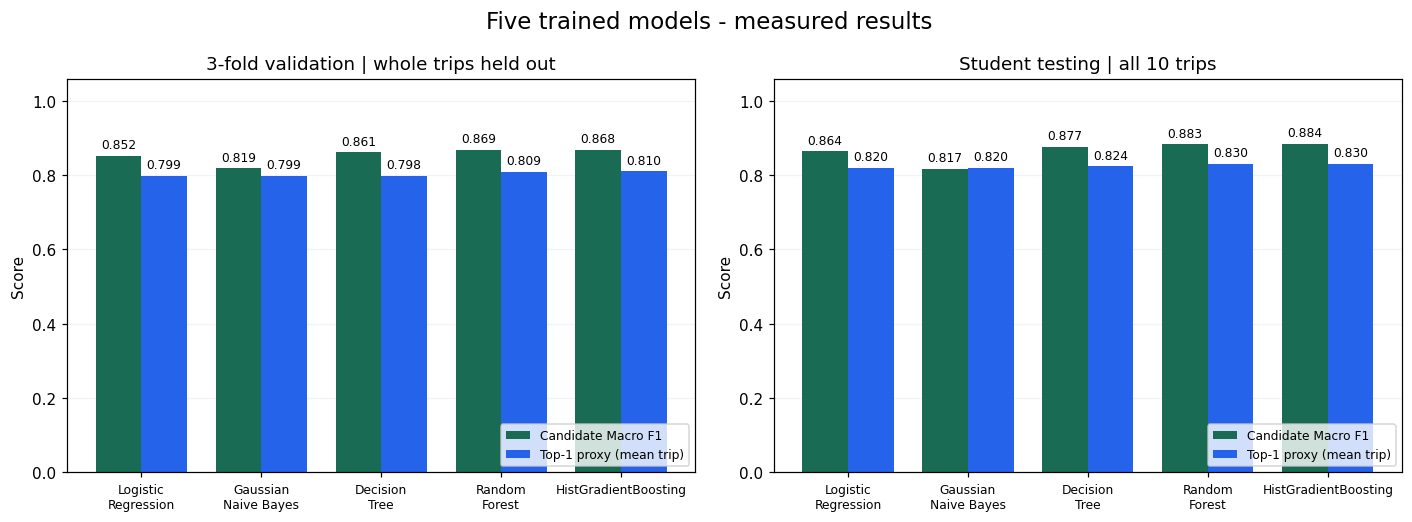

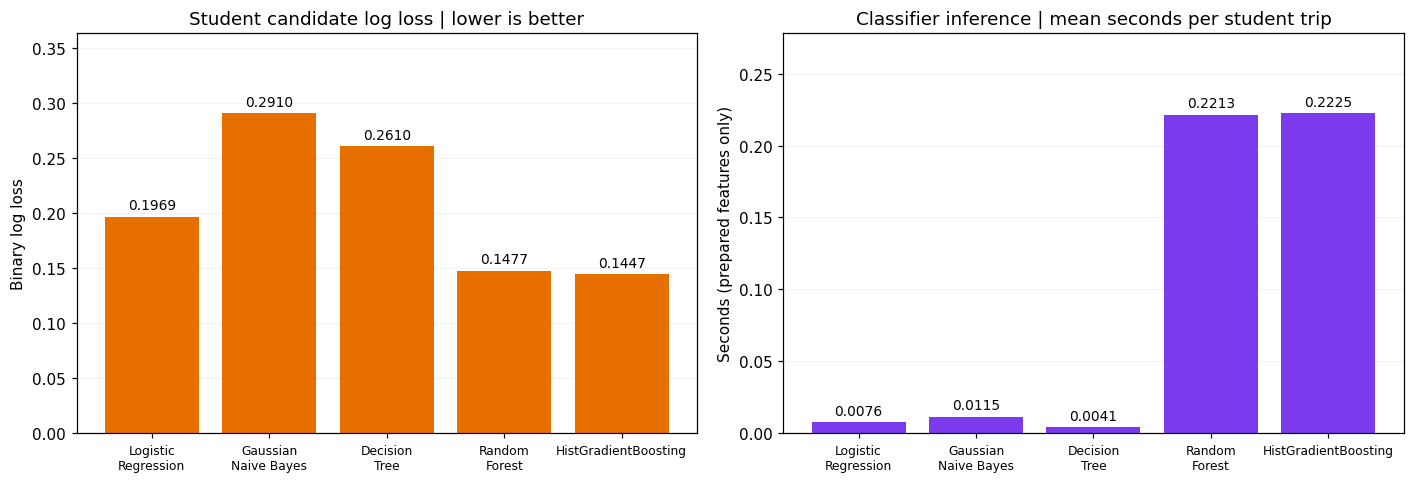

In [6]:
score_fig, efficiency_fig = comparison_figures(ROOT)
display(score_fig)
display(efficiency_fig)
plt.close(score_fig)
plt.close(efficiency_fig)

HGB narrowly leads CV Top-1; Random Forest narrowly leads CV candidate Macro F1.
The differences are small relative to fold variability. Classifier time excludes
raw loading, candidate generation, maps and network communication.

### 6. Actual candidate confusion matrices

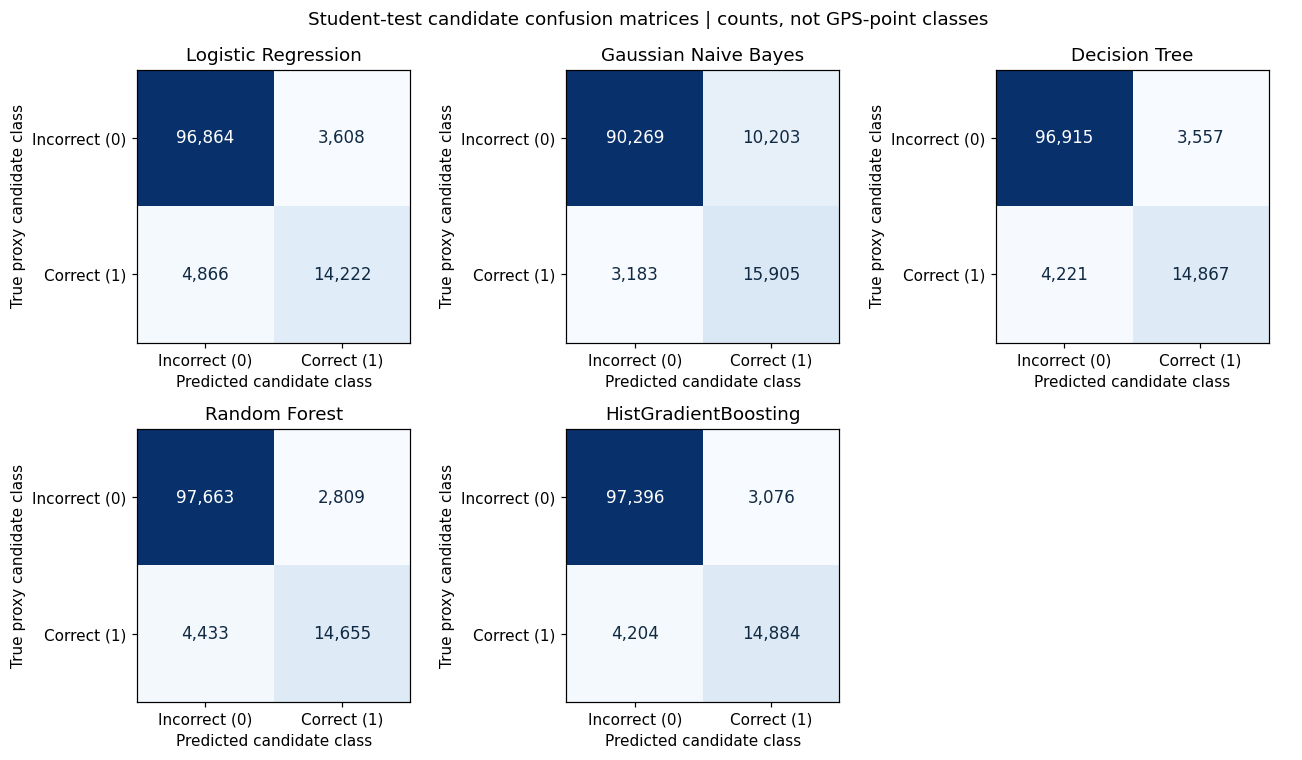

In [7]:
confusion = confusion_figure(ROOT)
display(confusion)
plt.close(confusion)

These matrices classify **candidate correctness (0/1)** against derived labels.
They do not classify the GPS points into five model classes.

### 7. Run the saved classifiers now on one trip
This cell performs a fresh `predict_proba` pass for each trained model on the
prepared feature tensor. It then displays actual selected arc IDs.
It does not rerun training or use reference labels as input features.

In [8]:
prediction_rows, fresh_scores, prediction_block = fresh_predictions(TRIP_ID, ROOT)
fresh_output = fresh_scores.copy()
fresh_output['model'] = fresh_output['model'].map(NAMES)
display(fresh_output.round(5))
display(prediction_rows.head(12))

,model,observations,aligned_points,trip_top1_proxy,fresh_classifier_seconds
0,Logistic Regression,2503,2503,0.91730,0.10829
1,Gaussian Naive Bayes,2503,2503,0.92209,0.01848
2,Decision Tree,2503,2503,0.92449,0.03347
3,Random Forest,2503,2503,0.92289,0.18926
4,HistGradientBoosting,2503,2503,0.92409,0.18036


,GPS row,reference proxy,logistic,naive_bayes,decision_tree,random_forest,hist_boost
0,0,17630,17630,17630,17630,17630,17630
1,1,17630,17630,17630,17630,17630,17630
2,2,17630,17630,17630,17630,17630,17630
3,3,17633,17633,17633,17633,17633,17633
4,4,17633,17633,17633,17633,17633,17633
5,5,211,211,211,211,211,211
6,6,211,211,211,211,211,211
7,7,211,211,211,211,211,211
8,8,211,211,211,211,211,211
9,9,17638,17638,17638,17638,17638,17638


### 8. One observation: candidate probabilities → chosen road
The selected model's actual candidate scores explain how its highest-scoring
candidate becomes one predicted road arc for a GPS row.

In [9]:
import joblib
from threadpoolctl import threadpool_limits
selected = joblib.load(ROOT / 'artifacts/selected.joblib')
mask = prediction_block['valid'][observation]
with threadpool_limits(limits=1):
    raw_scores = selected['model'].predict_proba(prediction_block['X'][observation, mask])[:, 1]
candidate_scores = pd.DataFrame({
    'arc_id': prediction_block['ids'][observation, mask],
    'distance_m': prediction_block['X'][observation, mask, 0],
    'raw_candidate_probability': raw_scores,
    'normalized_score': raw_scores.clip(1e-9) / raw_scores.clip(1e-9).sum()
}).sort_values('raw_candidate_probability', ascending=False)
print('Model:', NAMES[run['selected_untuned_model']], '| GPS observation:', observation)
display(candidate_scores.round(5))
print('Chosen arc ID:', int(candidate_scores.iloc[0].arc_id))

Model: HistGradientBoosting | GPS observation: 0


,arc_id,distance_m,raw_candidate_probability,normalized_score
0,17630,6.114290,0.62212,0.58750
1,17634,6.114290,0.37622,0.35528
2,17635,27.673401,0.03807,0.03595
3,17668,27.673401,0.01859,0.01756
4,212,46.000561,0.00239,0.00225
5,17633,46.000561,0.00154,0.00146


Chosen arc ID: 17630


## Checks
Verify the five models, whole-trip fold membership, and fresh predictions
against the saved per-trip measurements.

In [10]:
folds = json.loads((ROOT / 'artifacts/cv_splits.json').read_text())
assert len(comparison) == 5 and len(run['models']) == 5
for fold in folds:
    assert set(fold['train_trips']).isdisjoint(fold['validation_trips'])
held_out = [trip for fold in folds for trip in fold['validation_trips']]
assert len(held_out) == len(set(held_out)) == 80
recorded = pd.read_csv(ROOT / 'artifacts/classifier_sequence_comparison.csv', dtype={'trip_id': str})
recorded = recorded[recorded.trip_id == TRIP_ID].set_index('model')
for row in fresh_scores.itertuples():
    assert np.isclose(row.trip_top1_proxy, recorded.loc[row.model, 'top1_accuracy_proxy'])
    assert row.observations == len(gps)
print('PASS: five trained models; whole-trip folds; 80 unique held-out trips.')
print('PASS: fresh predictions match the saved trip scores for all five models.')
print('No Bayesian optimisation or HMM evaluation has been run.')

PASS: five trained models; whole-trip folds; 80 unique held-out trips.
PASS: fresh predictions match the saved trip scores for all five models.
No Bayesian optimisation or HMM evaluation has been run.


## Next steps
This demonstration stops at model comparison, as requested.
Change `TRIP_ID` and Run All to show a different student-test trip.
The original training commands remain in README.md if an evaluator asks you
to reproduce the experiment; this notebook intentionally avoids retraining
while presenting outputs.